<a href="https://colab.research.google.com/github/edoardo2496/data_science_portfolio/blob/main/TimesFM-NVDA-Quant/TimesFM_NVDA_Quant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 NVIDIA Stock Price Forecasting with Google TimesFM
* **Author:** Edoardo
* **Domain:** Quantitative Finance & Time Series Foundation Models
* **Objective:** Perform zero-shot price forecasting and risk quantification (confidence intervals) on NVIDIA (`NVDA`) daily closing prices using Google's pre-trained **TimesFM** model.
* **Environment:** Google Colab (Recommended Runtime: T4 GPU)

##Section 1: Environment Setup

In [12]:
# Install the latest stable version of TimesFM and yfinance
!pip install -q timesfm yfinance matplotlib numpy pandas

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timesfm
import yfinance as yf

# Set professional plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment successfully set up.")

Environment successfully set up.


## Section 2: Data Ingestion & Preprocessing
### Downloading NVIDIA (`NVDA`) historical price data via Yahoo Finance and cleaning the time series to make it compatible with the TimesFM model.

In [13]:
# Configuration parameters
TICKER = "NVDA"
START_DATE = "2022-01-01"

print(f"Downloading historical data for {TICKER} from {START_DATE}...")
df = yf.download(TICKER, start=START_DATE, progress=False)

# Handle potential MultiIndex columns in recent yfinance versions
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Clean and store into df_stoks_sorted as requested
df_stoks_sorted = df[['Close']].dropna().reset_index()
df_stoks_sorted.rename(columns={'Date': 'ds', 'Close': 'y'}, inplace=True)
df_stoks_sorted['unique_id'] = TICKER

# Extract raw prices as a clean numpy array for TimesFM
prices = df_stoks_sorted['y'].to_numpy().flatten()

print(f"Dataset successfully prepared: {len(prices)} trading days loaded.")

/tmp/ipykernel_474/423872189.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(TICKER, start=START_DATE, progress=False)


Dataset successfully prepared: 1222 trading days loaded.


## Section 3: Configuration & TimesFM Execution
###Initialization of Google's foundational model (`timesfm`) and generation of zero-shot forecasts, extracting risk quantiles (confidence bands) for the NVIDIA stock price.

In [14]:
# Define forecast horizon (e.g., 20 future trading days ~ 1 month)
horizon = 20

print("Loading TimesFM pre-trained foundational model...")
# Load the official pre-trained PyTorch model
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(
    "google/timesfm-2.5-200m-pytorch",
    torch_compile=False  # Disabled for smooth execution on Colab T4 GPU
)

# Configure the forecasting parameters via ForecastConfig
model.compile(
    timesfm.ForecastConfig(
        max_context=512,
        max_horizon=horizon,
        normalize_inputs=True,
        use_continuous_quantile_head=True,
        fix_quantile_crossing=True,
    )
)

print("Running zero-shot inference...")
# Execute inference without requiring custom gradient descent training
point_forecast, quantile_forecast = model.forecast(
    horizon=horizon,
    inputs=[prices]
)

# Extract mean predictions and risk boundaries (10th and 90th percentiles)
previsione_media = point_forecast[0]
limite_inferiore = quantile_forecast[0, :, 1]  # Bearish scenario (Q10)
limite_superiore = quantile_forecast[0, :, 9]  # Bullish scenario (Q90)

print("Inference completed successfully!")

Loading TimesFM pre-trained foundational model...
Running zero-shot inference...
Inference completed successfully!


## Section 4: Visualization & Risk Analysis
###Plotting the recent historical context alongside the model's mean trajectory and 80% confidence interval bands.

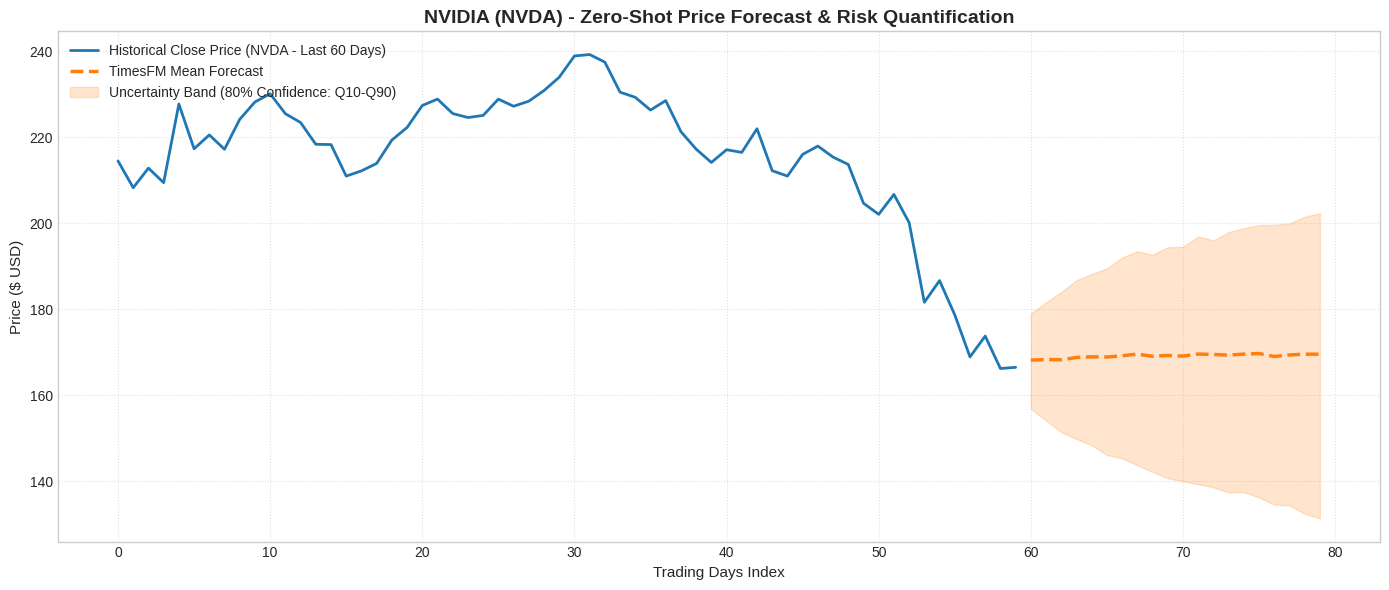


--- FORECAST SUMMARY TABLE ---


,Date,Mean Forecast ($),Bearish Scenario (Q10),Bullish Scenario (Q90)
0,2026-11-16,168.139999,156.809998,179.000000
1,2026-11-17,168.289993,154.070007,181.580002
2,2026-11-18,168.220001,151.419998,183.990005
3,2026-11-19,168.750000,149.789993,186.720001
4,2026-11-20,168.910004,148.339996,188.179993
5,2026-11-23,168.850006,146.070007,189.490005
6,2026-11-24,169.149994,145.279999,191.990005
7,2026-11-25,169.539993,143.679993,193.479996
8,2026-11-26,169.029999,142.149994,192.639999
9,2026-11-27,169.229996,140.649994,194.389999


In [15]:
# Slice recent history for clean visualization (e.g., last 60 trading days)
recent_history = prices[-60:]
future_dates_idx = np.arange(len(recent_history), len(recent_history) + horizon)
history_dates_idx = np.arange(len(recent_history))

# Generate future business dates for tabular view
last_date = df_stoks_sorted['ds'].iloc[-1]
future_business_dates = pd.bdate_range(start=last_date + pd.Timedelta(days=1), periods=horizon)

# Plotting
plt.figure(figsize=(14, 6))
plt.plot(history_dates_idx, recent_history, label=f"Historical Close Price ({TICKER} - Last 60 Days)", color="#1f77b4", linewidth=2)
plt.plot(future_dates_idx, previsione_media, label="TimesFM Mean Forecast", color="#ff7f0e", linestyle="--", linewidth=2.5)
plt.fill_between(future_dates_idx, limite_inferiore, limite_superiore, color="#ff7f0e", alpha=0.2, label="Uncertainty Band (80% Confidence: Q10-Q90)")

plt.title(f"NVIDIA ({TICKER}) - Zero-Shot Price Forecast & Risk Quantification", fontsize=14, fontweight="bold")
plt.xlabel("Trading Days Index", fontsize=11)
plt.ylabel("Price ($ USD)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Structured summary dataframe
forecast_summary_df = pd.DataFrame({
    'Date': future_business_dates,
    'Mean Forecast ($)': np.round(previsione_media, 2),
    'Bearish Scenario (Q10)': np.round(limite_inferiore, 2),
    'Bullish Scenario (Q90)': np.round(limite_superiore, 2)
})

print("\n--- FORECAST SUMMARY TABLE ---")
display(forecast_summary_df.head(10))